# Student Performance Prediction Using Machine Learning

## Project Objective

The objective of this project is to develop an end-to-end machine learning
model to predict a student's mathematics score using demographic,
educational and examination-related information.

The project includes data understanding, exploratory data analysis,
data preprocessing, multiple machine learning models, model evaluation,
model comparison, hyperparameter tuning and prediction on unseen data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load the Dataset

The StudentsPerformance dataset is loaded using pandas. The dataset is
then inspected to understand its size and structure before performing
data preprocessing and analysis.

In [2]:
df = pd.read_csv("StudentsPerformance (1).csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 2. Understanding the Dataset

In this section, we examine the structure of the dataset, including the
number of rows and columns, column names, data types, and basic statistical
information.

This helps us understand which variables are numerical and which are
categorical before performing preprocessing.

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of rows: 1000
Number of columns: 8

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


## 3. Checking Data Types

The data types of all columns are checked to identify numerical and
categorical variables.

This information is important because different preprocessing techniques
are required for numerical and categorical features.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


## 4. Statistical Summary

The describe() function provides statistical information about numerical
features, such as count, mean, standard deviation, minimum, maximum and
quartile values.

This helps us understand the general distribution of the numerical data.

In [5]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 5. Checking Missing Values

Missing values can cause problems during machine learning model training.
Therefore, we check each column for missing values.

If missing values are present, an appropriate imputation technique can be
applied. If there are no missing values, no imputation is necessary.

In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


## 6. Checking Duplicate Rows

Duplicate records are checked because repeated observations can affect
model training and may give unnecessary importance to the same data.

If duplicates are found, they can be removed after verification.

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 7. Checking Categorical Variables

The unique values of categorical columns are examined to understand the
different categories present in the dataset.

In [8]:
categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


gender:
['female' 'male']

race/ethnicity:
['group B' 'group C' 'group A' 'group D' 'group E']

parental level of education:
["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

lunch:
['standard' 'free/reduced']

test preparation course:
['none' 'completed']


## 8. Identifying Numerical Variables

The score columns are numerical variables. These variables can be directly
used for numerical analysis and visualization.

In [9]:
numerical_columns = [
    "math score",
    "reading score",
    "writing score"
]

print("Numerical columns:")
print(numerical_columns)

Numerical columns:
['math score', 'reading score', 'writing score']


## 9. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution,
patterns and relationships present in the dataset.

First, we analyze the distributions of mathematics, reading and writing
scores using histograms.

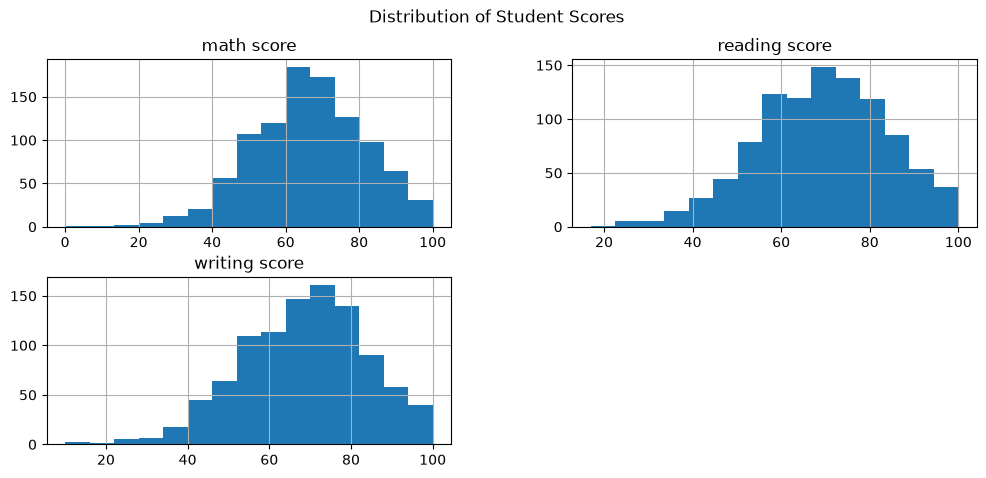

In [10]:
score_columns = ["math score", "reading score", "writing score"]

df[score_columns].hist(
    figsize=(12, 5),
    bins=15
)

plt.suptitle("Distribution of Student Scores")
plt.show()

## 10. Boxplot Analysis

Boxplots are used to understand the spread of the numerical score variables
and to identify potential outliers.

Outliers are not automatically removed because an unusual score can still
represent a valid student observation.

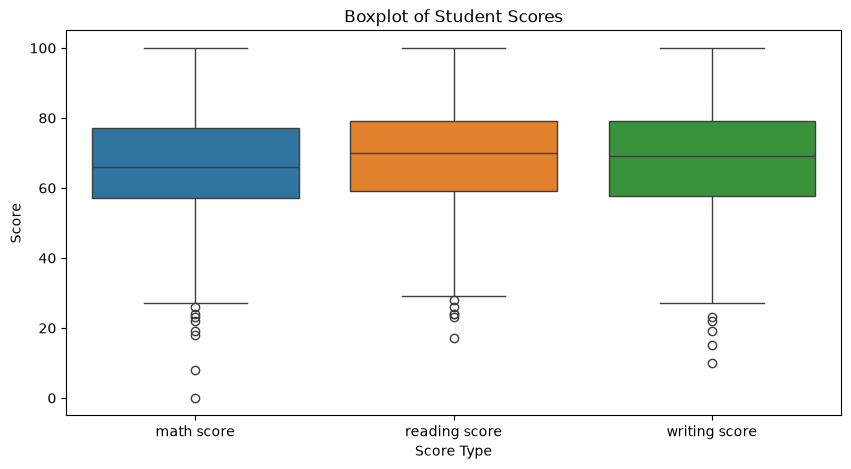

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[score_columns])

plt.title("Boxplot of Student Scores")
plt.xlabel("Score Type")
plt.ylabel("Score")

plt.show()

## 11. Math Score by Gender

A boxplot is used to compare mathematics scores across gender categories.

This visualization helps us understand whether the distribution of
mathematics scores differs between the groups.

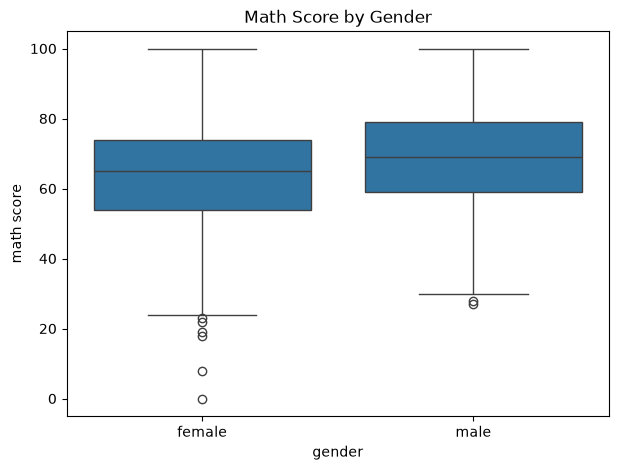

In [12]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="gender",
    y="math score"
)

plt.title("Math Score by Gender")
plt.show()

## 12. Effect of Test Preparation on Math Score

The relationship between completion of the test preparation course and
mathematics performance is visualized.

This helps us understand whether the test preparation feature may contain
useful information for predicting mathematics scores.

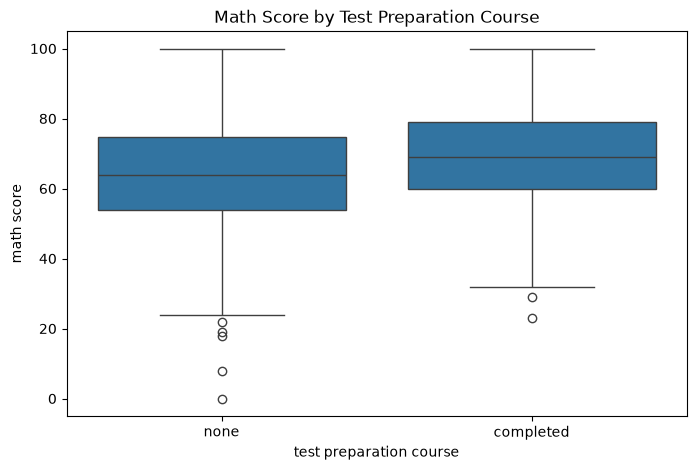

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="test preparation course",
    y="math score"
)

plt.title("Math Score by Test Preparation Course")
plt.show()

## 13. Parental Level of Education and Math Score

The distribution of mathematics scores across different parental education
levels is visualized.

This helps us explore whether parental education may be associated with
student mathematics performance.

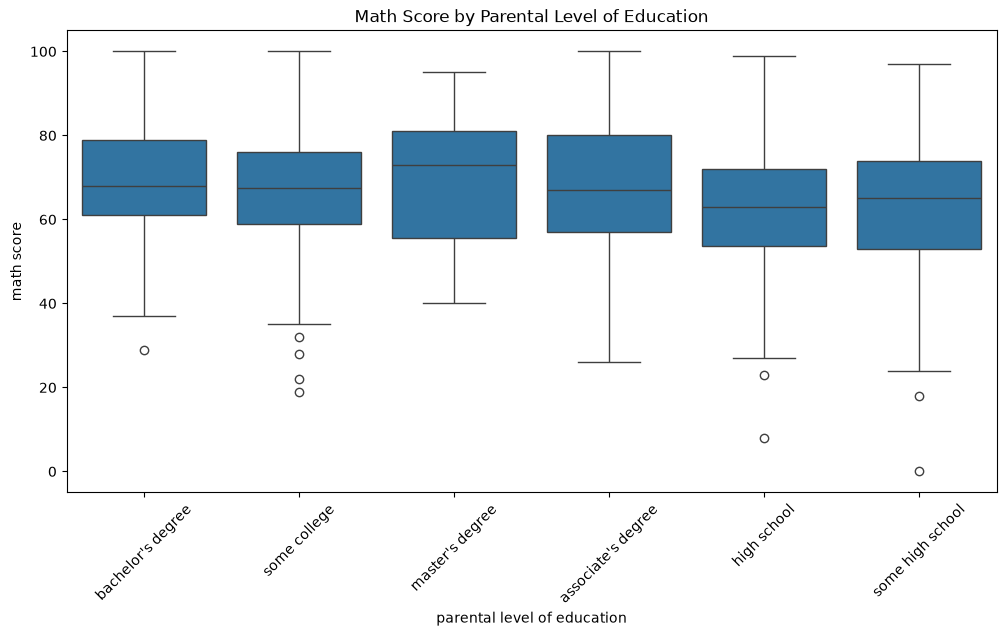

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="parental level of education",
    y="math score"
)

plt.xticks(rotation=45)
plt.title("Math Score by Parental Level of Education")

plt.show()

## 14. Correlation Analysis

Correlation analysis is performed for the numerical variables to understand
the strength and direction of their linear relationships.

Reading score and writing score are particularly important because they may
have a strong relationship with mathematics score.

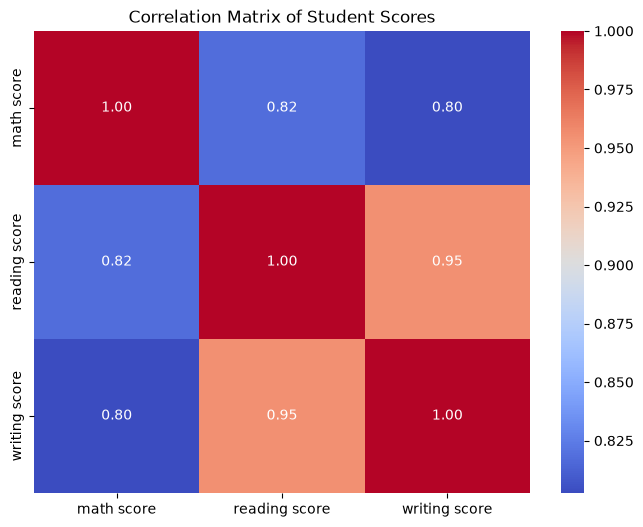

In [15]:
correlation_matrix = df[score_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Student Scores")
plt.show()

## 15. Reading Score vs Math Score

A scatter plot is used to visualize the relationship between reading score
and mathematics score.

This helps us determine whether higher reading scores tend to be associated
with higher mathematics scores.

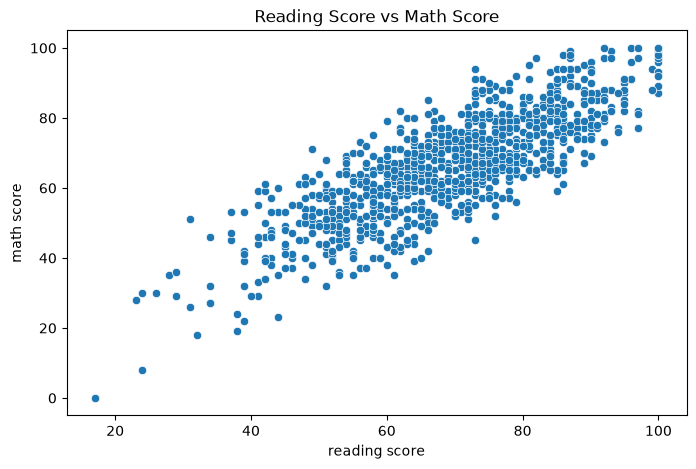

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="reading score",
    y="math score"
)

plt.title("Reading Score vs Math Score")
plt.show()

## 16. Writing Score vs Math Score

A scatter plot is used to visualize the relationship between writing score
and mathematics score.

The pattern in the plot helps determine whether writing performance can be
a useful predictor of mathematics performance.

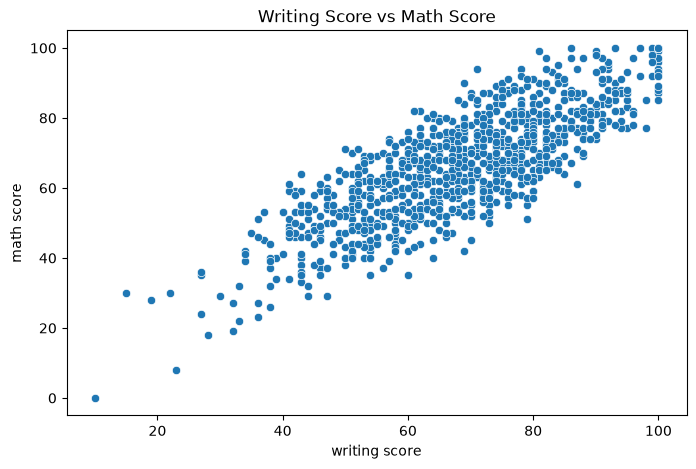

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="writing score",
    y="math score"
)

plt.title("Writing Score vs Math Score")
plt.show()

## 17. Feature Selection

The objective of this project is to predict the student's mathematics score.

Therefore, `math score` is selected as the target variable.

The remaining relevant student information is used as input features.

In [18]:
X = df.drop("math score", axis=1)
y = df["math score"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print("math score")

Input Features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'reading score', 'writing score']

Target Variable:
math score


## 18. Identifying Feature Types

The input variables consist of categorical and numerical features.

Categorical features contain groups or categories, while numerical features
contain numerical values.

Identifying these types allows us to apply appropriate preprocessing methods.

In [19]:
categorical_features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

numerical_features = [
    "reading score",
    "writing score"
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

Numerical Features:
['reading score', 'writing score']


## 19. Splitting the Dataset

The dataset is divided into training and testing sets.

80% of the data is used for training the machine learning models and 20% is
reserved for testing.

The test data is not used during model training, allowing us to evaluate the
model on unseen data.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 7)
Testing data: (200, 7)


## 20. Data Preprocessing

The dataset contains both categorical and numerical features.

Categorical variables are converted into numerical representation using
One-Hot Encoding.

Numerical features are standardized using StandardScaler so that they are
on a comparable scale.

A ColumnTransformer is used to apply the appropriate preprocessing technique
to each type of feature.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 21. Building Multiple Machine Learning Models

Since the target variable is a numerical mathematics score, regression
algorithms are appropriate.

Five different models are selected for comparison:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Random Forest Regressor
5. Gradient Boosting Regressor

Comparing multiple models helps us identify which algorithm performs best
for this dataset.

In [22]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(alpha=0.1),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

print("Models created:")
for model_name in models:
    print("-", model_name)

Models created:
- Linear Regression
- Ridge Regression
- Lasso Regression
- Random Forest
- Gradient Boosting


## 22. Model Training

Each machine learning model is combined with the preprocessing pipeline
using a Pipeline.

The models are then trained using the training dataset.

Using a pipeline ensures that preprocessing is performed consistently
without leaking information from the test dataset into the training process.

In [23]:
from sklearn.pipeline import Pipeline

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Linear Regression trained successfully!
Ridge Regression trained successfully!
Lasso Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


## 23. Making Predictions

After training, each model is used to predict mathematics scores for the
unseen test dataset.

These predictions will be compared with the actual mathematics scores
during model evaluation.

In [24]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(f"{name}: Predictions generated")

Linear Regression: Predictions generated
Ridge Regression: Predictions generated
Lasso Regression: Predictions generated
Random Forest: Predictions generated
Gradient Boosting: Predictions generated


## 24. Model Evaluation

The trained models are evaluated using three regression metrics:

- MAE: Measures the average absolute prediction error.
- RMSE: Measures prediction error while giving greater weight to larger errors.
- R² Score: Measures how much variation in the target variable is explained
  by the model.

For MAE and RMSE, lower values are better.
For R² Score, a higher value is better.

In [25]:
results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.214763,5.393994,0.880433
1,Ridge Regression,4.211113,5.390418,0.880592
2,Lasso Regression,4.154489,5.368405,0.881565
3,Random Forest,4.620434,5.982683,0.852911
4,Gradient Boosting,4.304522,5.576656,0.872198


## 25. Comparing Machine Learning Models

The evaluation results are arranged according to R² Score to identify the
model with the strongest predictive performance.

A higher R² Score indicates better performance, while lower MAE and RMSE
indicate lower prediction errors.

In [26]:
comparison = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

comparison

,Model,MAE,RMSE,R2 Score
0,Lasso Regression,4.154489,5.368405,0.881565
1,Ridge Regression,4.211113,5.390418,0.880592
2,Linear Regression,4.214763,5.393994,0.880433
3,Gradient Boosting,4.304522,5.576656,0.872198
4,Random Forest,4.620434,5.982683,0.852911


## 26. Model Performance Visualization

A bar chart is created to visually compare the R² Score of the different
machine learning models.

This makes it easier to identify the model that provides the best
predictive performance.

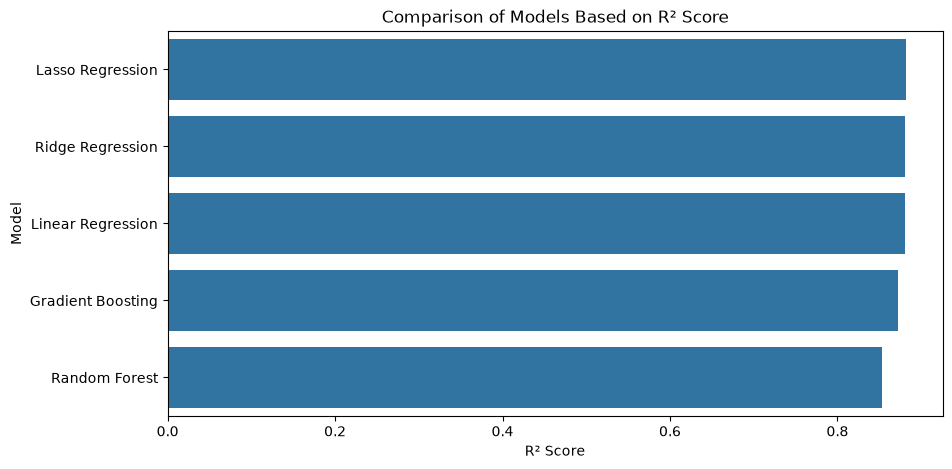

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="R2 Score",
    y="Model"
)

plt.title("Comparison of Models Based on R² Score")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.show()

## 27. Comparison of Evaluation Metrics

All three evaluation metrics are visualized to understand the performance
of each model.

For MAE and RMSE, smaller values indicate better performance.
For R² Score, a larger value indicates better performance.

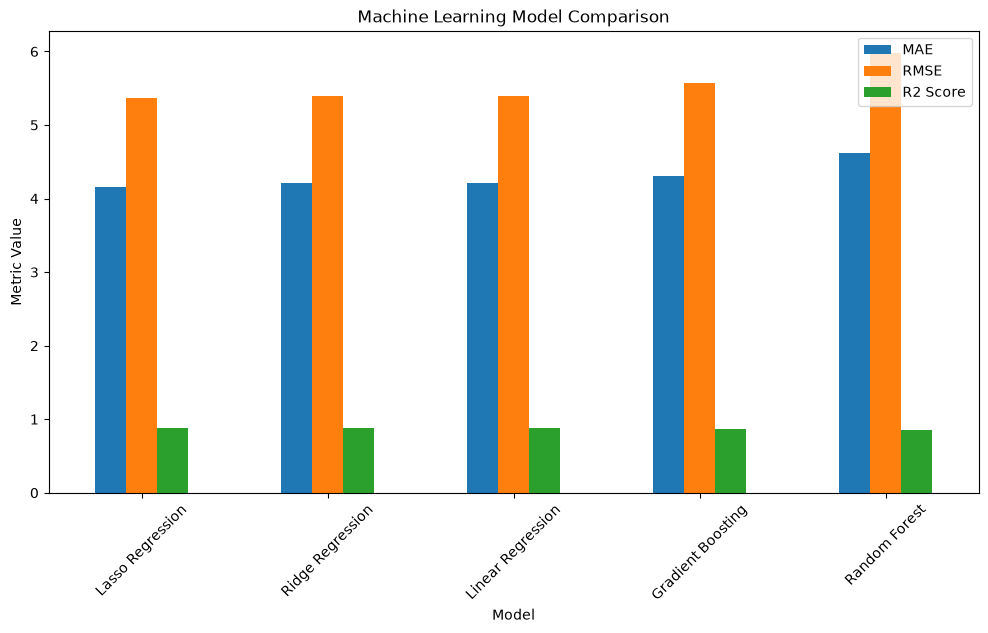

In [28]:
comparison.set_index("Model")[["MAE", "RMSE", "R2 Score"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=45)
plt.legend()
plt.show()

## 28. Selecting the Best Model

The model with the highest R² Score is selected as the best-performing model
among the models tested.

However, MAE and RMSE are also considered to ensure that the selected model
has relatively low prediction error.

In [29]:
best_model_name = comparison.iloc[0]["Model"]

print("Best Model:", best_model_name)

print("\nPerformance:")
print(comparison.iloc[0])

Best Model: Lasso Regression

Performance:
Model       Lasso Regression
MAE                 4.154489
RMSE                5.368405
R2 Score            0.881565
Name: 0, dtype: object


## 29. Hyperparameter Tuning

Hyperparameters control how a machine learning algorithm learns from the
data.

GridSearchCV is used to test different combinations of Random Forest
hyperparameters using 5-fold cross-validation.

The combination that produces the best cross-validation R² Score is selected.

In [30]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestRegressor(
            random_state=42
        )
    )
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R² Score:")
print(grid_search.best_score_)

Best Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross-Validation R² Score:
0.8387831172019574


## 30. Evaluation of the Tuned Model

The best Random Forest model obtained from GridSearchCV is evaluated on the
unseen test dataset.

This allows us to determine whether hyperparameter tuning improved the
model's performance.

In [31]:
tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_predictions
    )
)

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²  :", tuned_r2)

Tuned Random Forest Results
---------------------------
MAE : 4.569992326072077
RMSE: 5.916092329129687
R²  : 0.856166768390081


## 31. Before and After Hyperparameter Tuning

The original Random Forest and tuned Random Forest are compared using the
same evaluation metrics.

This helps determine whether hyperparameter tuning provided an improvement.

In [32]:
original_rf = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0]

tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        original_rf["MAE"],
        tuned_mae
    ],
    "RMSE": [
        original_rf["RMSE"],
        tuned_rmse
    ],
    "R2 Score": [
        original_rf["R2 Score"],
        tuned_r2
    ]
})

tuning_comparison

,Model,MAE,RMSE,R2 Score
0,Original Random Forest,4.620434,5.982683,0.852911
1,Tuned Random Forest,4.569992,5.916092,0.856167


## 32. Actual vs Predicted Values

The actual mathematics scores are compared with the scores predicted by the
tuned model.

If the predictions are close to the actual values, the model is performing
well.

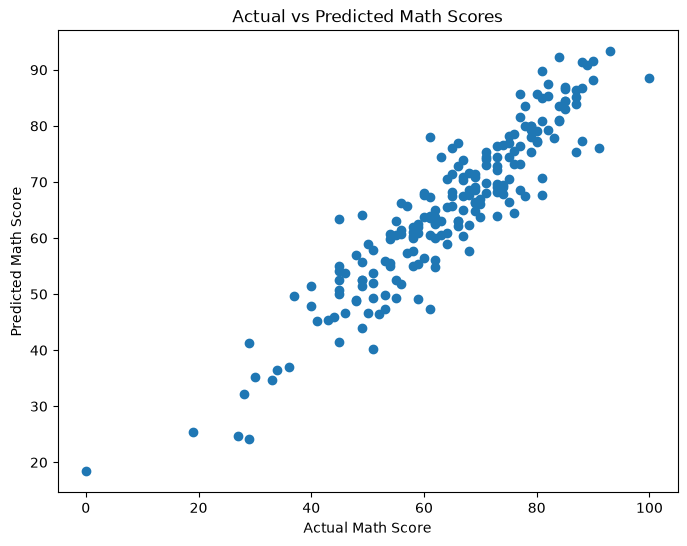

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_predictions
)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("Actual vs Predicted Math Scores")

plt.show()

## 33. Prediction Error Analysis

Prediction errors are calculated as the difference between actual and
predicted mathematics scores.

The distribution of errors helps us understand how the model's predictions
deviate from the actual values.

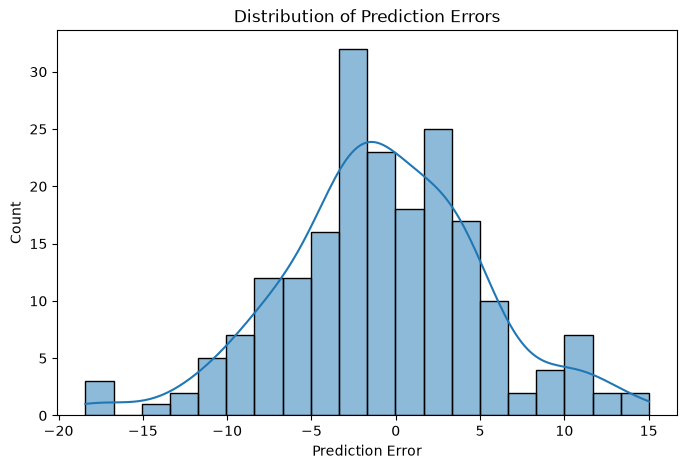

In [34]:
errors = y_test - tuned_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    errors,
    bins=20,
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.show()

## 34. Prediction on New / Unseen Data

The final tuned model is used to predict the mathematics score of a new
student.

This student record was not used during model training or testing, which
demonstrates how the completed machine learning system can make predictions
for new observations.

In [35]:
new_student = pd.DataFrame({
    "gender": ["female"],
    "race/ethnicity": ["group B"],
    "parental level of education": ["bachelor's degree"],
    "lunch": ["standard"],
    "test preparation course": ["completed"],
    "reading score": [80],
    "writing score": [85]
})

predicted_math_score = tuned_model.predict(new_student)

print(
    "Predicted Math Score:",
    round(predicted_math_score[0], 2)
)

Predicted Math Score: 72.32


## 17. Statistical Regression Analysis Using OLS

Ordinary Least Squares (OLS) regression is used to study the statistical
relationship between mathematics score and the reading and writing scores.

The OLS summary provides R² and P-values. R² indicates how much variation
in mathematics score is explained by the predictors, while the P-value
helps determine whether an individual predictor has a statistically
significant relationship with the target variable.

A commonly used significance level is 0.05. A P-value below 0.05 indicates
statistical significance.

In [37]:
import statsmodels.api as sm

X_ols = df[["reading score", "writing score"]]
y_ols = df["math score"]

X_ols = sm.add_constant(X_ols)

ols_model = sm.OLS(y_ols, X_ols).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:             math score   R-squared:                       0.674
Model:                            OLS   Adj. R-squared:                  0.673
Method:                 Least Squares   F-statistic:                     1031.
Date:                Tue, 01 Sep 2026   Prob (F-statistic):          2.25e-243
Time:                        15:17:46   Log-Likelihood:                -3576.9
No. Observations:                1000   AIC:                             7160.
Df Residuals:                     997   BIC:                             7175.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             7.5241      1.328      5.665